<a href="https://colab.research.google.com/github/dtabuena/Resources/blob/main/Art/Diagrams_and_Schematics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diagrams and Schematics

Cartoon and schematic recipes for figures and graphical abstracts. Every section runs on random stand-in data, so nothing here depends on a real dataset.

Shared setup runs once below. Each schematic after that is self-contained.

In [ ]:
import urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

response = urllib.request.urlretrieve('https://raw.githubusercontent.com/dtabuena/Resources/main/Matplotlib_Config/drt_mpl_config.py', 'drt_mpl_config.py')
%run drt_mpl_config.py

dt_config v2.1
Matplotlib_config load success
colorspacious is not installed; optional '!pip install colorspacious'
hue_seurat defined but needs colorspacious to run
display_dt_customs() to display maps


<Figure size 450x450 with 0 Axes>

## 96-Well Plate Cartoon

One plate, full circles, black outlines. Green well passed, orange well failed, at a random 10 percent failure rate.

Text-stripped relative to the source figure: tick labels (A-H, 1-12), plate title, legend, and the summary prints are all gone.

In [ ]:
PLATE_FIGSIZE = (.75, .5)

# 96 wells
EMPTY_COLOR = 'lightgray'         # was #CCCCCC, unused while the plate is full
SUCCESS_COLOR = 'mediumseagreen'  # was #4CAF50, green  - passed
FAILURE_COLOR = 'darkorange'      # was #F57C00, orange - failed
OUTLINE_COLOR = 'k'

ROW_LABELS = list('ABCDEFGH')
N_ROWS = 8
N_COLS = 12
WELL_RADIUS = 0.40

FAILURE_RATE = 0.10
RANDOM_SEED = 0
COL_LABELS = [f'{col_number}' for col_number in range(1, 13)]
LABEL_GUTTER = 0.9   # top and left, holds the labels
EDGE_BUFFER = 0.4    # bottom and right, empty margin

In [ ]:
"""Random stand-in for well_status: one row per well, pass or fail."""

random_generator = np.random.default_rng(RANDOM_SEED)

all_wells = [f'{row_letter}{col_number:02d}'
             for row_letter in ROW_LABELS
             for col_number in range(1, N_COLS + 1)]

well_status = pd.DataFrame({
    'well': all_wells,
    'passed': random_generator.random(len(all_wells)) >= FAILURE_RATE,
})

,well,passed
0,A01,True
1,A02,True
2,A03,False
3,A04,False
4,A05,True


In [ ]:
def well_to_rc(well_name):
    """Convert 'A01' -> (row_index, col_index) zero-based."""
    row_letter = well_name[0]
    if row_letter not in ROW_LABELS:
        raise ValueError(f"Unrecognized row letter '{row_letter}' in well '{well_name}'")
    row_index = ROW_LABELS.index(row_letter)
    col_index = int(well_name[1:]) - 1
    return row_index, col_index


def draw_well(target_axis, col_index, row_index, face_color):
    """One full circle per well. Linewidth comes from the config rcParams."""
    target_axis.add_patch(mpl.patches.Circle((col_index, -row_index), WELL_RADIUS,
                                             facecolor=face_color,
                                             edgecolor=OUTLINE_COLOR))


def plot_plate(target_axis, status_frame):
    for _row_label, well_row in status_frame.iterrows():
        row_index, col_index = well_to_rc(well_row['well'])
        face_color = SUCCESS_COLOR if well_row['passed'] else FAILURE_COLOR
        draw_well(target_axis, col_index, row_index, face_color)


    # Labels sit in a gutter inside the frame; the far sides get a plain margin
    target_axis.set_xlim(-0.5 - LABEL_GUTTER, N_COLS - 0.5 + EDGE_BUFFER)
    target_axis.set_ylim(-(N_ROWS - 0.5 + EDGE_BUFFER), 0.5 + LABEL_GUTTER)

    label_x = -0.5 - LABEL_GUTTER / 2
    label_y = 0.5 + LABEL_GUTTER / 2
    for col_index, col_label in enumerate(COL_LABELS):
        target_axis.text(col_index, label_y, col_label, ha='center', va='center',fontsize=4)
    for row_index, row_label in enumerate(ROW_LABELS):
        target_axis.text(label_x, -row_index, row_label, ha='center', va='center',fontsize=4)

    target_axis.set_xticks([])
    target_axis.set_yticks([])
    target_axis.set_aspect('equal')

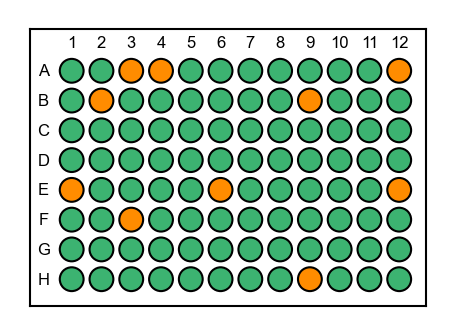

In [ ]:
fig, panel_axis = plt.subplots(figsize=PLATE_FIGSIZE)

plot_plate(panel_axis, well_status)

plt.tight_layout()
plt.show()
fig.savefig('ninety-six_well.svg')

# Sample Traces

In [ ]:
ABF_NAME = 'sample_gain.abf'
ABF_URL = f'https://raw.githubusercontent.com/dtabuena/Resources/main/Art/{ABF_NAME}'
response = urllib.request.urlretrieve(ABF_URL, ABF_NAME)
ABF_PATH = ABF_NAME

In [ ]:
!pip install pyabf

In [ ]:
import pyabf


abf = pyabf.ABF(ABF_PATH)

abf_summary = pd.DataFrame({
    'Property': ['Sweep Count', 'Channel Count', 'Sample Rate (Hz)',
                 'Sweep Length (s)', 'Protocol', 'X Label', 'Y Label'],
    'Value': [abf.sweepCount, abf.channelCount, abf.dataRate,
              abf.sweepLengthSec, abf.protocol, abf.sweepLabelX, abf.sweepLabelY],
})
display(abf_summary)

,Property,Value
0,Sweep Count,21
1,Channel Count,2
2,Sample Rate (Hz),10000
3,Sweep Length (s),5.0
4,Protocol,IC - Gain - D10pA
5,X Label,Time (seconds)
6,Y Label,Membrane Potential (mV)


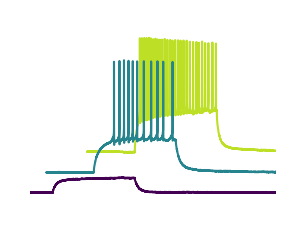

In [ ]:
SWEEP_FIGSIZE = (1, .75)
SWEEP_INDICES = [2, 4, 7][::1]
X_LIMITS = (.3, 2.3)            # (start_seconds, stop_seconds), or None for the whole sweep
SWEEP_CMAP = 'viridis'
CMAP_RANGE = (0, .9)    # skip the white end, see note
SWEEP_OFFSET = (.5, 20)   # (seconds, mV) added per step through SWEEP_INDICES
sweep_cmap = mpl.colormaps[SWEEP_CMAP]
z_dir = 1


if len(SWEEP_INDICES) == 1:
    sweep_colors = ['k']
else:
    sweep_colors = [sweep_cmap(position)
                    for position in np.linspace(*CMAP_RANGE, len(SWEEP_INDICES))]

fig, trace_axis = plt.subplots(figsize=SWEEP_FIGSIZE)

for draw_order, (sweep_index, sweep_color) in enumerate(zip(SWEEP_INDICES, sweep_colors)):
    abf.setSweep(sweep_index)
    offset_x = draw_order * SWEEP_OFFSET[0]
    offset_y = draw_order * SWEEP_OFFSET[1]
    trace_axis.plot(abf.sweepX + offset_x, abf.sweepY + offset_y, color=sweep_color,
                    zorder=z_dir*(len(SWEEP_INDICES) - draw_order))

if X_LIMITS is not None:
    total_offset_x = (len(SWEEP_INDICES) - 1) * SWEEP_OFFSET[0]
    trace_axis.set_xlim(X_LIMITS[0], X_LIMITS[1] + total_offset_x)

trace_axis.set_xticks([])
trace_axis.set_yticks([])
trace_axis.set_frame_on(False)

plt.tight_layout()
plt.show()

fig.savefig('ephys_gain.svg')

# Corr Matrix

In [ ]:
import scipy as sci

In [ ]:
N_CELLS = 20000
N_GENES = 100
N_GENE_MODULES = 20
N_LATENT = 10
N_CELL_TYPES = 15

SIGNAL_FRACTION = 0.45
MODULE_JITTER = 0.60
CELL_TYPE_SEPARATION = 2.5
RANDOM_SEED = 0

random_generator = np.random.default_rng(RANDOM_SEED)

# A gene module is a shared loading vector; jitter keeps genes in it from being clones
module_assignment = np.repeat(np.arange(N_GENE_MODULES), N_GENES // N_GENE_MODULES)
module_loadings = random_generator.normal(size=(N_GENE_MODULES, N_LATENT))
gene_loadings = (module_loadings[module_assignment]
                 + MODULE_JITTER * random_generator.normal(size=(N_GENES, N_LATENT)))

# A cell type is a location in latent space; cells scatter around their type centre
cell_type_labels = random_generator.integers(0, N_CELL_TYPES, size=N_CELLS)
cell_type_centers = random_generator.normal(scale=CELL_TYPE_SEPARATION,
                                            size=(N_CELL_TYPES, N_LATENT))
cell_latent = (cell_type_centers[cell_type_labels]
               + random_generator.normal(size=(N_CELLS, N_LATENT)))

expression_noise = random_generator.normal(size=(N_CELLS, N_GENES))
expression = (SIGNAL_FRACTION * (cell_latent @ gene_loadings.T)
              + (1 - SIGNAL_FRACTION) * expression_noise)

# Every cell gets an embedding; the plots decide which ones to draw
centered_expression = expression - expression.mean(axis=0)
left_vectors, singular_values, _ = np.linalg.svd(centered_expression, full_matrices=False)
embedding = left_vectors[:, :2] * singular_values[:2]

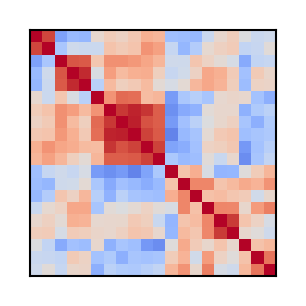

In [ ]:
CORR_FIGSIZE = (1, 1)
CORR_N_CELLS = 20


correlation_generator = np.random.default_rng(RANDOM_SEED)
correlation_cells = correlation_generator.choice(N_CELLS, CORR_N_CELLS, replace=False)

cell_correlation = np.corrcoef(expression[correlation_cells])

condensed_distance = sci.spatial.distance.squareform(1.0 - cell_correlation, checks=False)
linkage_matrix = sci.cluster.hierarchy.linkage(condensed_distance, method='average')
leaf_order = sci.cluster.hierarchy.leaves_list(linkage_matrix)

cell_correlation = cell_correlation[np.ix_(leaf_order, leaf_order)]
# np.fill_diagonal(cell_correlation, np.nan)

fig, corr_axis = plt.subplots(figsize=CORR_FIGSIZE)
corr_axis.imshow(cell_correlation, cmap='coolwarm', norm=mpl.colors.CenteredNorm())
corr_axis.set_xticks([])
corr_axis.set_yticks([])
# corr_axis.set_frame_on(False)

plt.tight_layout()
plt.show()

fig.savefig('cell_correlation.svg', bbox_inches='tight')

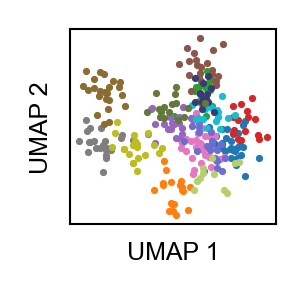

In [ ]:
UMAP_FIGSIZE = (1, 1)
UMAP_N_CELLS = 300
MARKER_SIZE = 3
CELL_TYPE_COLOR_STRIDE = 2

umap_generator = np.random.default_rng(RANDOM_SEED)
umap_cells = umap_generator.choice(N_CELLS, UMAP_N_CELLS, replace=False)

fig, umap_axis = plt.subplots(figsize=UMAP_FIGSIZE)
for cell_type_index in range(N_CELL_TYPES):
    in_type = umap_cells[cell_type_labels[umap_cells] == cell_type_index]
    umap_axis.scatter(embedding[in_type, 0], embedding[in_type, 1],
                      color=tab60(cell_type_index * CELL_TYPE_COLOR_STRIDE),
                      s=MARKER_SIZE, linewidths=0)

umap_axis.set_xticks([])
umap_axis.set_yticks([])
umap_axis.set_xlabel('UMAP 1')
umap_axis.set_ylabel('UMAP 2')
umap_axis.set_aspect('equal')

plt.tight_layout()
plt.show()

fig.savefig('cell_umap.svg', bbox_inches='tight')

## Volcanoe

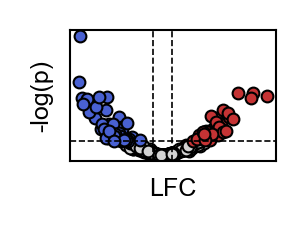

In [ ]:
VOLCANO_FIGSIZE = (1, .75)

N_GENES = 300
EFFECT_SCALE = .7
SE_SHAPE = 40.0
SE_SCALE = 0.0075
FOLD_CHANGE_THRESHOLD = .20
PVALUE_THRESHOLD = 0.01
MARKER_SIZE = 8
RANDOM_SEED = 0

volcano_generator = np.random.default_rng(RANDOM_SEED)

# Model the measurement, not the picture: each gene gets its own standard error
# and significance is the effect divided by it. That ratio is what curves the wings.
standard_error = volcano_generator.gamma(SE_SHAPE, SE_SCALE, size=N_GENES)
true_effect = volcano_generator.normal(scale=EFFECT_SCALE, size=N_GENES)
log2_fold_change = true_effect + volcano_generator.normal(scale=standard_error)
t_statistic = log2_fold_change / standard_error
p_value = 2.0 * sci.stats.norm.sf(np.abs(t_statistic))
neg_log10_p = -np.log10(np.clip(p_value, 1e-300, None))

significance_cutoff = -np.log10(PVALUE_THRESHOLD)
is_significant = neg_log10_p >= significance_cutoff
is_up = is_significant & (log2_fold_change >= FOLD_CHANGE_THRESHOLD)
is_down = is_significant & (log2_fold_change <= -FOLD_CHANGE_THRESHOLD)
is_flat = ~(is_up | is_down)

coolwarm = mpl.colormaps['coolwarm']

fig, volcano_axis = plt.subplots(figsize=VOLCANO_FIGSIZE)
volcano_axis.scatter(log2_fold_change[is_flat], neg_log10_p[is_flat],
                     color='lightgrey', s=MARKER_SIZE, edgecolors='k', linewidths=.5)
volcano_axis.scatter(log2_fold_change[is_down], neg_log10_p[is_down],
                     color=coolwarm(0.05), s=MARKER_SIZE, edgecolors='k', linewidths=.5)
volcano_axis.scatter(log2_fold_change[is_up], neg_log10_p[is_up],
                     color=coolwarm(0.95), s=MARKER_SIZE, edgecolors='k', linewidths=.5)

volcano_axis.axhline(significance_cutoff, color='k', linestyle='--', linewidth=0.4)
volcano_axis.axvline(FOLD_CHANGE_THRESHOLD, color='k', linestyle='--', linewidth=0.4)
volcano_axis.axvline(-FOLD_CHANGE_THRESHOLD, color='k', linestyle='--', linewidth=0.4)

volcano_axis.set_xticks([])
volcano_axis.set_yticks([])
volcano_axis.set_xlabel('LFC')
volcano_axis.set_ylabel('-log(p)')

plt.tight_layout()
plt.show()

fig.savefig('volcano.svg', bbox_inches='tight')

# Pathways

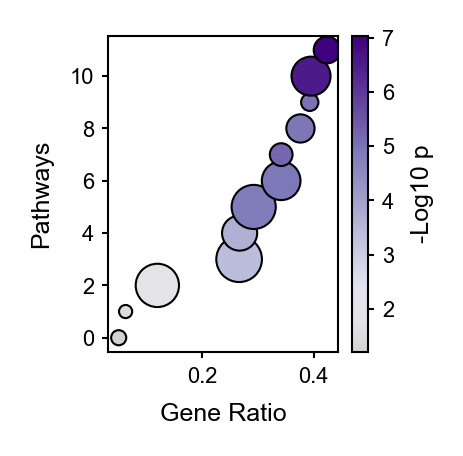

In [ ]:
PATHWAY_FIGSIZE = (1.5, 1.5)

N_PATHWAYS = 12
PATHWAY_SIZE_RANGE = (15, 250)
GENE_RATIO_RANGE = (0.05, 0.45)
DOT_AREA_RANGE = (10.0, 120.0)
DOT_EDGE_WIDTH = 0.5
RANDOM_SEED = 0

pathway_generator = np.random.default_rng(RANDOM_SEED)

pathway_gene_count = pathway_generator.integers(*PATHWAY_SIZE_RANGE, size=N_PATHWAYS)
gene_ratio = pathway_generator.uniform(*GENE_RATIO_RANGE, size=N_PATHWAYS)
# Bigger ratios tend to be more significant, which is what makes a dot plot readable
pathway_neg_log10_p = gene_ratio * 12.0 + pathway_generator.gamma(1.5, 0.8, size=N_PATHWAYS)

rank_order = np.argsort(gene_ratio)
pathway_gene_count = pathway_gene_count[rank_order]
gene_ratio = gene_ratio[rank_order]
pathway_neg_log10_p = pathway_neg_log10_p[rank_order]

count_span = pathway_gene_count.max() - pathway_gene_count.min()
dot_area = (DOT_AREA_RANGE[0]
            + (pathway_gene_count - pathway_gene_count.min()) / count_span
            * (DOT_AREA_RANGE[1] - DOT_AREA_RANGE[0]))

fig, dot_axis = plt.subplots(figsize=PATHWAY_FIGSIZE)
dot_points = dot_axis.scatter(gene_ratio, np.arange(N_PATHWAYS),
                              s=dot_area, c=pathway_neg_log10_p,
                              cmap=Purples_grey,
                              linewidths=DOT_EDGE_WIDTH, edgecolors='k')
# dot_axis.set_yticks([])
dot_axis.set_xlabel('Gene Ratio')
dot_axis.set_ylabel('Pathways')

color_bar = fig.colorbar(dot_points, ax=dot_axis)
color_bar.set_label('-Log10 p')

plt.tight_layout()
plt.show()

fig.savefig('pathway_dotplot.svg', bbox_inches='tight')